# Avance 2 — Ingeniería de características

**Equipo 39 · Proyecto Integrador MNA**

Estudiantes:
- Isabella Arango Restrepo - A01796305
- Manuel Alejandro Vázquez Meza - A01796404
- Isaí Ambrocio - A01625101

Este cuaderno integra tres frentes: (1) escalamiento y adimensionalización, (2) selección de características e información de Fisher, y (3) análisis estadístico experimental NIST Marshall. Se conservan las metodologías y conclusiones originales de cada frente.

**Ejecución:** los frentes 1 y 2 requieren el repositorio del equipo, su paquete `src/pinn_mems` y los archivos de `datos/sinteticos`. Ejecutar desde una copia local del repositorio o desde un entorno Colab donde esté clonado.

In [8]:

# ============================================================
# 0. PREPARACIÓN DEL ENTORNO
# ============================================================

!git clone --branch PINNs-semana-4 \
    https://github.com/isabellaarangor/proyecto-integrador-team39-MNA.git

%cd /content/proyecto-integrador-team39-MNA

!pip install -q -e .


Cloning into 'proyecto-integrador-team39-MNA'...
remote: Enumerating objects: 412, done.
remote: Counting objects: 100% (412/412), done.
remote: Compressing objects: 100% (291/291), done.
remote: Total 412 (delta 144), reused 304 (delta 102), pack-reused 0 (from 0)
Receiving objects: 100% (412/412), 8.85 MiB | 10.43 MiB/s, done.
Resolving deltas: 100% (144/144), done.
/content/proyecto-integrador-team39-MNA
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for pinn-mems (pyproject.toml) ... done


In [9]:
# ============================================================
# 0. IMPORTACIONES Y CONFIGURACIÓN COMPARTIDA
# ============================================================

# Biblioteca estándar
import sys
import warnings
from dataclasses import replace
from pathlib import Path

# Bibliotecas de terceros
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import f, shapiro, ttest_ind
from statsmodels.stats.anova import AnovaRM

# Localizar el repositorio antes de importar el paquete del equipo.
repo_candidates = (Path.cwd(), *Path.cwd().resolve().parents)
RAIZ = next(
    (path.resolve() for path in repo_candidates
     if (path / "src" / "pinn_mems").is_dir()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró src/pinn_mems. Abre el notebook desde el "
        "repositorio del equipo o clónalo antes de ejecutarlo."
    )

src_path = str(RAIZ / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from pinn_mems import Soporte, Viga, cargar_config, generar, resolver_modos
from pinn_mems.adimensional import Escalas, desescalar, escalar
from pinn_mems.colocacion import cota_cramer_rao, fisher, puntos
from pinn_mems.escalamiento import (
    elasticidad_kappa,
    magnitudes,
    ordenes_de_magnitud,
    terminos_de_perdida,
)
from pinn_mems.ingenieria_caracteristicas import (
    cocientes_frecuencia,
    direcciones_fisher,
    matriz_correlacion,
    pca_svd,
    seleccionar_puntos_varianza,
    varianza_formas,
)

CONFIGS = RAIZ / "datos" / "sinteticos" / "configs"
CALIBRACION = pd.read_csv(RAIZ / "datos" / "sinteticos" / "calibracion.csv")
VIGA = Viga(E=70e9, L=300e-6, b=28e-6, h=2.743e-6, rho=2200.0)
ESC = Escalas.desde_viga(VIGA)

pd.set_option("display.float_format", lambda value: f"{value:.3g}")
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e6e3",
        "figure.dpi": 110,
    }
)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]

# Frente 1 — Escalamiento

# Escalamiento de características

Esta sección explica cómo llevamos todas las magnitudes del problema a una escala comparable antes de estimar el módulo de Young. Se ejecuta completa de principio a fin (*Run All*) desde el repositorio, en unos segundos.

**En tres frases:**
1. En unidades del Sistema Internacional, una viga microscópica mezcla números de $10^{-23}$ (su momento de inercia) con números de $10^{11}$ (su módulo de Young), y eso hace casi imposible entrenar una red neuronal o ajustar un modelo.
2. En lugar de las técnicas de escalamiento habituales (min-max o estandarización), **adimensionalizamos**: dividimos cada cantidad entre una escala física de la propia viga, con lo que las ecuaciones conservan su forma y todo queda cerca de 1.
3. Además, las cantidades que recorren varios órdenes de magnitud, como la rigidez del anclaje, se trabajan en **escala logarítmica**.

**Contenido**
1. [El problema: magnitudes muy distintas](#1.-El-problema:-magnitudes-muy-distintas)
2. [La técnica: adimensionalizar](#2.-La-técnica:-adimensionalizar)
3. [Por qué no min-max ni estandarización](#3.-Por-qué-no-min-max-ni-estandarización)
4. [Transformación logarítmica de la rigidez del anclaje y de E](#4.-Transformación-logarítmica-de-la-rigidez-del-anclaje-y-de-E)
5. [Conclusión](#5.-Conclusión)

### Términos

| Término | Significado |
|---|---|
| **Módulo de Young, E** | Qué tan rígido es el material. Es lo que queremos estimar |
| **Voladizo / biempotrada** | Viga sujeta de un extremo (como un trampolín) / de los dos (como un puente) |
| **Forma modal, w(x)** | La forma que toma la viga al vibrar en uno de sus modos; su amplitud es arbitraria |
| **Momento flector, M** | El esfuerzo interno que dobla la viga |
| **Esfuerzo residual, σ₀** | Tensión o compresión que queda en la viga al fabricarla |
| **Rigidez del anclaje, k_θ y k_u** | Qué tanto cede el soporte al giro (k_θ) y al desplazamiento (k_u). Infinita = soporte perfecto |
| **Eigensolver** | Nuestro programa de referencia que calcula frecuencias y formas modales de una viga |
| **PINN** | Red neuronal informada por la física: se entrena para ajustar los datos y cumplir las ecuaciones de la viga a la vez |
| **Término de pérdida** | Cada parte del error que la PINN minimiza: ajuste a los datos y cumplimiento de cada ecuación |
| **Severidades s1–s6** | Seis niveles de anclaje cada vez más flexible en los datos sintéticos (s1 casi perfecto, s6 el más flexible) |
| **RM 8096** | Material de referencia del NIST (vigas de óxido de silicio) cuya geometría usamos |

### Preparación

Esta celda localiza el código del proyecto (`src/pinn_mems`) y carga las librerías. Requiere `numpy`, `scipy`, `pyyaml`, `matplotlib` y `pandas`.

## 1. El problema: magnitudes muy distintas

Tomamos un voladizo de 300 µm de largo, 28 µm de ancho y 2.7 µm de espesor, con la geometría del material de referencia del NIST, vibrando en su primer modo con una amplitud de 10 nm. La tabla muestra el tamaño típico de cada cantidad en unidades del Sistema Internacional (columna `si`) y en forma adimensional (columna `adimensional`; vacía para las cantidades que desaparecen al agruparse con otras).

In [10]:
tabla = pd.DataFrame(magnitudes(VIGA))
print(f"Órdenes de magnitud en SI: {ordenes_de_magnitud(tabla['si']):.0f}")
print(f"Órdenes de magnitud en forma adimensional: {ordenes_de_magnitud(tabla['adimensional'].dropna()):.1f}")
tabla

Órdenes de magnitud en SI: 33
Órdenes de magnitud en forma adimensional: 2.3


,cantidad,simbolo,unidad,si,adimensional
0,Longitud,L → ξ,m,0.0003,1
1,Espesor,h,m,2.74e-06,NaN
2,Momento de inercia,I,m⁴,4.82e-23,NaN
3,Módulo de Young,E → θ = E/E_ref,Pa,7e+10,1
4,Densidad,ρ,kg/m³,2.2e+03,NaN
5,Desplazamiento,w → W,m,1e-08,1
6,Momento flector,M → M̂,N·m,1.32e-12,3.52
7,Frecuencia angular,ω → λ,rad/s,1.74e+05,12.4
8,Esfuerzo residual,σ₀ → n,Pa,5e+06,10.3
9,Rigidez rotacional del anclaje,k_θ → κ_θ,N·m/rad,8.55e-07,76.1


Lo que importa para entrenar no son las cantidades sueltas sino los **términos de pérdida**: la PINN suma el error de ajuste a los datos y el error en cada ecuación, y si uno de esos términos es $10^{15}$ veces mayor que otro, el optimizador solo "ve" el grande y los demás no se entrenan.

La tabla siguiente muestra el tamaño típico (media del cuadrado a lo largo de la viga) de cada término en tres versiones: en SI, en forma adimensional y con el ajuste adicional que usa la PINN (dividir cada ecuación entre la escala del modo, $\sqrt{\lambda}$ o $\lambda$). La carga axial se calcula con el esfuerzo residual de la viga biempotrada (−5 MPa) sobre la misma forma, solo para comparar su tamaño.

In [11]:
perdidas = pd.DataFrame(terminos_de_perdida(VIGA))
for col in ("si", "adimensional", "pinn"):
    print(f"{col:>12}: {ordenes_de_magnitud(perdidas[col]):4.1f} órdenes de magnitud")
perdidas

          si: 16.1 órdenes de magnitud
adimensional:  3.1 órdenes de magnitud
        pinn:  0.9 órdenes de magnitud


,termino,expresion,unidad,si,adimensional,pinn
0,Datos,w² → W²,m²,2.51e-17,0.251,0.251
1,Física r₁ (momento),(E·I·w″)² → W″²,N²·m²,4.35e-25,3.1,0.251
2,Física r₂ (flexión),(E·I·w⁗)² → M̂″²,N²/m²,6.63e-10,38.3,0.251
3,Física r₂ (inercia),(ρA·ω²·w)² → (λ·W)²,N²/m²,6.63e-10,38.3,0.251
4,Física r₂ (carga axial),(N·w″)² → (n·W″)²,N²/m²,5.64e-09,326,2.13


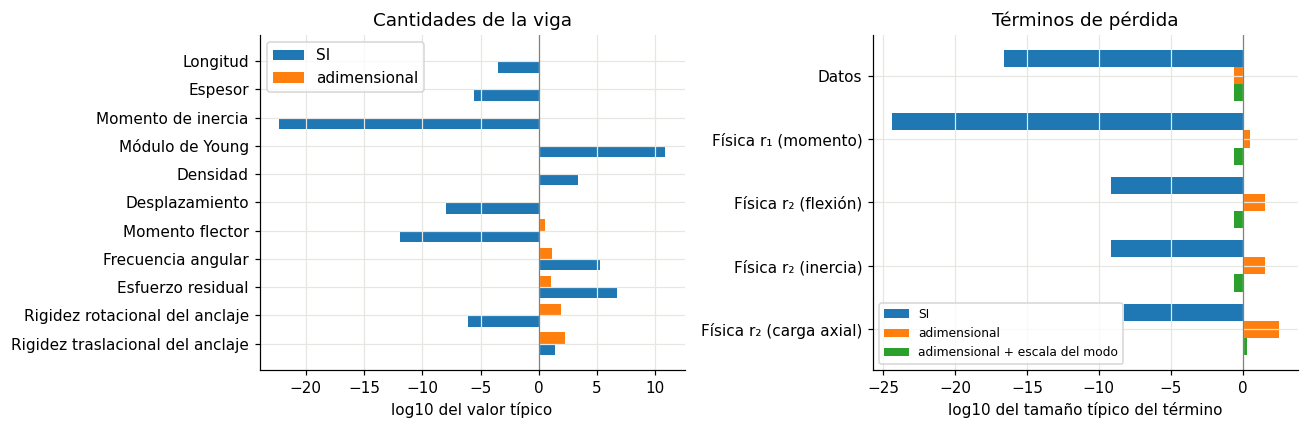

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

orden = np.arange(len(tabla))
ejes[0].barh(orden + 0.2, np.log10(tabla["si"]), height=0.4, label="SI")
ejes[0].barh(orden - 0.2, np.log10(tabla["adimensional"].astype(float)), height=0.4, label="adimensional")
ejes[0].set_yticks(orden, tabla["cantidad"])
ejes[0].invert_yaxis()
ejes[0].set_xlabel("log10 del valor típico")
ejes[0].set_title("Cantidades de la viga")
ejes[0].legend()

orden = np.arange(len(perdidas))
for j, (col, nombre) in enumerate((("si", "SI"), ("adimensional", "adimensional"), ("pinn", "adimensional + escala del modo"))):
    ejes[1].barh(orden + (j - 1) * 0.27, np.log10(perdidas[col]), height=0.27, label=nombre)
ejes[1].set_yticks(orden, perdidas["termino"])
ejes[1].invert_yaxis()
ejes[1].set_xlabel("log10 del tamaño típico del término")
ejes[1].set_title("Términos de pérdida")
ejes[1].legend(fontsize=8, loc="lower left")
for ax in ejes:
    ax.axvline(0, color="gray", lw=0.8)
fig.tight_layout()
plt.show()

En SI las cantidades abarcan más de 30 órdenes de magnitud y los términos de pérdida unos 16. En forma adimensional, todo queda entre 1 y unos cientos; con la escala del modo, los términos de pérdida quedan prácticamente en el mismo nivel (entre 0.25 y 2).

## 2. La técnica: adimensionalizar

Adimensionalizar es dividir cada cantidad entre una escala de la propia viga, elegida para que las ecuaciones queden sin constantes físicas:

| Cantidad | Variable adimensional | Escala |
|---|---|---|
| Posición $x$ | $\xi = x/L$ | Longitud de la viga |
| Desplazamiento $w$ | $W = w/h$ (o normalizado a pico 1) | Espesor |
| Momento flector $M$ | $\hat{M} = M L^2/(E I h)$ | Rigidez a flexión |
| Frecuencia $\omega$ | $\lambda = \omega^2 \rho A L^4/(E I)$ | Frecuencia natural de la viga |
| Esfuerzo residual $\sigma_0$ | $n = \sigma_0 A L^2/(E I)$ | Carga de pandeo |
| Rigidez del anclaje $k_\theta$, $k_u$ | $\kappa_\theta = k_\theta L/(E I)$, $\kappa_u = k_u L^3/(E I)$ | Rigidez de la viga |
| Módulo de Young $E$ | $\theta = E/E_{ref}$ | Valor nominal del material |

Con estos grupos, las dos ecuaciones que usa la PINN quedan simplemente

$$\hat{M} - W'' = 0, \qquad \hat{M}'' - n\,W'' - \lambda\,W = 0,$$

donde la prima indica derivada respecto de $\xi$. Son los mismos grupos con los que trabaja el eigensolver por dentro, así que el método de referencia y la PINN usan exactamente la misma interfaz.

La celda siguiente comprueba dos cosas: que el $\lambda$ que calcula el eigensolver es el que se obtiene al adimensionalizar su frecuencia, y que la conversión de ida y vuelta recupera los valores originales sin pérdida.

In [13]:
modos = resolver_modos(VIGA, "voladizo", n_modos=3)
print("λ del eigensolver:          ", np.round(modos.lam, 4))
print("λ adimensionalizando ω:     ", np.round(ESC.a_lambda(modos.omega), 4))

viga_tensa = Viga(E=70e9, L=300e-6, b=28e-6, h=2.743e-6, rho=2200.0, sigma0=-5e6)
adim = escalar(viga_tensa, modos.omega, k_theta=1e-7, k_u=5.0)
vuelta = desescalar(adim, viga_tensa)
print("Error relativo de ida y vuelta en ω:  ", np.max(np.abs(vuelta["omega"] / modos.omega - 1)))
print("Error relativo de ida y vuelta en σ₀: ", abs(vuelta["sigma0"] / viga_tensa.sigma0 - 1))

λ del eigensolver:           [  12.3624  485.5188 3806.5463]
λ adimensionalizando ω:      [  12.3624  485.5188 3806.5463]
Error relativo de ida y vuelta en ω:   2.220446049250313e-16
Error relativo de ida y vuelta en σ₀:  2.220446049250313e-16


## 3. Por qué no min-max ni estandarización

Las técnicas de escalamiento del curso (min-max, que lleva cada variable a $[0, 1]$, y la estandarización, que le resta su media y la divide entre su desviación estándar) funcionan bien para características de una tabla, pero aquí fallan por tres razones:

1. **Dependen de la muestra.** Los factores de escala salen de los datos (su mínimo, máximo, media o desviación), así que dos mediciones de la misma viga, con distinto ruido o distintos puntos, quedan escaladas de forma distinta. La adimensionalización solo depende de la geometría y del material nominal.
2. **Rompen las ecuaciones.** Min-max resta el mínimo: la condición "la viga no se mueve en el anclaje", $W(0) = 0$, deja de cumplirse, y la ecuación de movimiento gana un término constante que no tiene sentido físico. Con la adimensionalización las ecuaciones conservan su forma exacta.
3. **No comparten escala entre métodos.** Cada método tendría su propia escala según sus datos; con la adimensionalización el eigensolver, la inversión clásica y la PINN trabajan con los mismos números, y la comparación entre ellos es justa.

La celda siguiente lo muestra con dos mediciones simuladas de la misma viga, que solo difieren en el ruido.

In [14]:
config = cargar_config(CONFIGS / "m0_voladizo.yaml")
filas = []
for semilla in (0, 1):
    config["ruido"]["semilla"] = semilla
    conjunto = generar(config)
    w = conjunto.w[1] * 10e-9  # segundo modo, amplitud de 10 nm
    filas.append({
        "medición": f"semilla {semilla}",
        "escala min-max (nm)": 1e9 * (w.max() - w.min()),
        "W(0) con min-max": (w[0] - w.min()) / (w.max() - w.min()),
        "W(0) estandarizado": (w[0] - w.mean()) / w.std(),
        "W(0) adimensional": w[0] / 10e-9,
        "λ adimensional": ESC.a_lambda(conjunto.omega[1]),
    })
pd.DataFrame(filas).set_index("medición")

,escala min-max (nm),W(0) con min-max,W(0) estandarizado,W(0) adimensional,λ adimensional
medición,,,,,
semilla 0,17.3,0.579,-0.434,0.0101,486
semilla 1,17.5,0.576,-0.485,-0.013,485


Usamos el segundo modo, que tiene desplazamientos positivos y negativos. En el anclaje la viga no se mueve, así que $W(0)$ debería valer cero:

- Con **min-max**, el anclaje queda en casi 0.6, y la escala (el rango de cada muestra) cambia con el ruido.
- Con la **estandarización**, el anclaje queda en un valor que depende de la media y la desviación de esa muestra en particular.
- En forma **adimensional**, el anclaje queda en cero salvo el ruido de la propia medición, y $\lambda$ solo cambia lo que cambia la frecuencia medida.

## 4. Transformación logarítmica de la rigidez del anclaje y de E

La rigidez adimensional del anclaje, $\kappa_\theta$, recorre más de un orden de magnitud entre las severidades de nuestros datos sintéticos, y vale infinito en el soporte perfecto:

In [15]:
severidades = pd.DataFrame(
    [{"severidad": f"s{i}", "κ_θ": cargar_config(CONFIGS / f"m1_voladizo_s{i}.yaml")["soporte"]["kappa_theta"]}
     for i in range(1, 7)]
).set_index("severidad")
severidades["ln κ_θ"] = np.log(severidades["κ_θ"])
severidades

,κ_θ,ln κ_θ
severidad,,
s1,396,5.98
s2,156,5.05
s3,76.1,4.33
s4,36.1,3.59
s5,22.8,3.13
s6,12.1,2.49


En escala lineal, casi toda la variación de la frecuencia ocurre cuando $\kappa_\theta$ es pequeño; para valores grandes la curva se aplana y un paso fijo del optimizador significa cosas muy distintas según dónde esté. En escala logarítmica la curva es suave en todo el rango.

La gráfica de la derecha muestra la **elasticidad** $\partial \ln \lambda / \partial \ln \kappa_\theta$: cuánto cambia la frecuencia (en %) por cada 1 % de cambio en la rigidez. Para $E$ esa misma cantidad vale exactamente −1 en cualquier punto, porque $\lambda$ es proporcional a $1/E$. Trabajar en $\ln E$ y $\ln \kappa_\theta$ hace que:

- un paso del optimizador sea un **cambio porcentual**, comparable en cualquier rango;
- las sensibilidades de los dos parámetros sean números sin unidades y comparables entre sí (por eso el análisis de cuánta información aportan los datos usa $\ln E$ y $\ln \kappa_\theta$);
- los parámetros sean siempre positivos sin tener que imponerlo aparte.

La PINN aplica la misma idea: el parámetro que entrena es $\ln \theta = \ln(E/E_{ref})$.

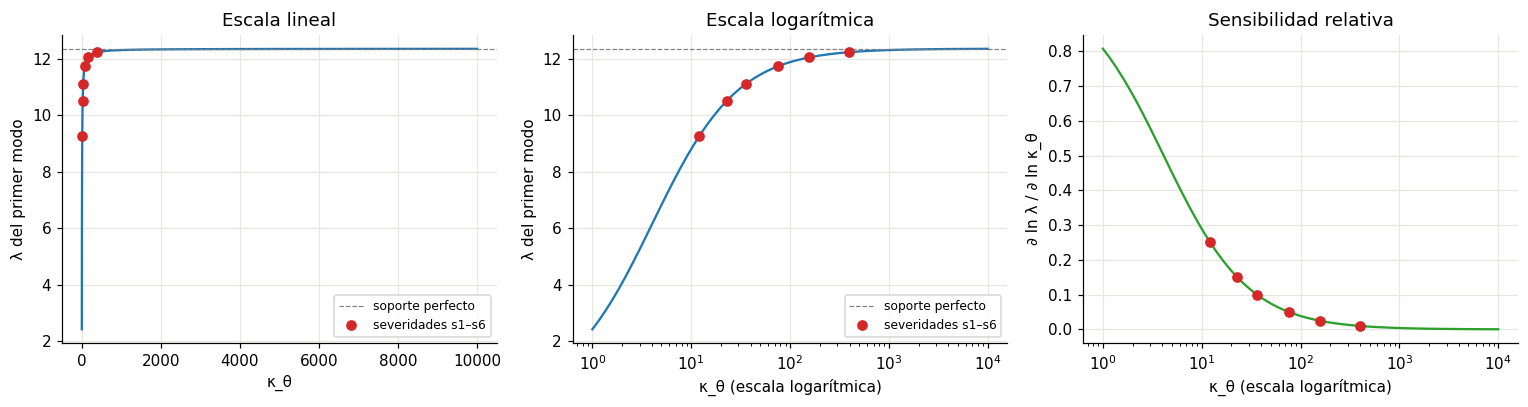

In [16]:
kappas = np.logspace(0, 4, 60)
lam1 = [resolver_modos(VIGA, "voladizo", Soporte(kappa_theta=k), n_modos=1).lam[0] for k in kappas]
lam_ideal = resolver_modos(VIGA, "voladizo", n_modos=1).lam[0]
elasticidad = elasticidad_kappa(VIGA, "voladizo", kappas)

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, escala in zip(ejes[:2], ("linear", "log")):
    ax.plot(kappas, lam1, "C0-")
    ax.axhline(lam_ideal, color="gray", ls="--", lw=0.8, label="soporte perfecto")
    ax.plot(severidades["κ_θ"], [np.interp(k, kappas, lam1) for k in severidades["κ_θ"]], "o", color="C3", label="severidades s1–s6")
    ax.set_xscale(escala)
    ax.set_xlabel("κ_θ" + (" (escala logarítmica)" if escala == "log" else ""))
    ax.set_ylabel("λ del primer modo")
    ax.legend(fontsize=8)
ejes[0].set_title("Escala lineal")
ejes[1].set_title("Escala logarítmica")
ejes[2].semilogx(kappas, elasticidad, "C2-")
ejes[2].plot(severidades["κ_θ"], np.interp(severidades["κ_θ"], kappas, elasticidad), "o", color="C3")
ejes[2].set_xlabel("κ_θ (escala logarítmica)")
ejes[2].set_ylabel("∂ ln λ / ∂ ln κ_θ")
ejes[2].set_title("Sensibilidad relativa")
fig.tight_layout()
plt.show()

La sensibilidad relativa cae de forma suave de 0.25 (anclaje muy flexible, s6) a 0.01 (casi perfecto, s1): en s3, por ejemplo, ignorar el anclaje cambia la frecuencia alrededor de 5 %, que es justo el nivel de severidad con que se diseñaron los datos.

## 5. Conclusión

- **Técnica elegida:** adimensionalización con escalas físicas de la viga, más la transformación logarítmica de $E$ y $\kappa_\theta$.
- **Efecto:** las cantidades pasan de abarcar más de 30 órdenes de magnitud a quedar entre 1 y unos cientos, y los términos de pérdida de la PINN pasan de unos 16 órdenes de magnitud a quedar todos entre 0.25 y 2.
- **Por qué esta y no min-max o estandarización:** no depende de la muestra, conserva las ecuaciones y sus condiciones de frontera, y es la misma escala para todos los métodos, lo que hace justa su comparación.
- **Por qué el logaritmo:** la rigidez del anclaje varía en órdenes de magnitud; en escala logarítmica los pasos del optimizador son cambios porcentuales y las sensibilidades de $E$ y $\kappa_\theta$ quedan comparables.

# Frente 2 — Selección

# Ingeniería de características para la inversión clásica

Esta sección prepara características para estimar propiedades físicas de vigas MEMS con el eigensolver del proyecto. El análisis de espectro y formas modales usa datos sintéticos M0 y M1, porque el conjunto real del Brazo 1 solo contiene la frecuencia fundamental por viga.

**En tres frases:** los cocientes entre frecuencias reducen la escala común asociada al módulo de Young; la varianza y la correlación ayudan a evaluar qué observaciones aportan información repetida o cambiante; la información de Fisher y el PCA cuantifican, respectivamente, sensibilidad local a parámetros y dimensión de las desviaciones modales.

### Contenido

1. Características espectrales
2. Filtrado por varianza
3. Correlación entre observaciones
4. Selección de ubicación y modos con Fisher
5. Extracción con PCA
6. Alcance y conclusión

## 1. Características espectrales

Para cada escenario calculamos $R_2=\omega_2/\omega_1$ y $R_3=\omega_3/\omega_1$. En ausencia de carga axial, al fijar los grupos adimensionales del soporte, un cambio de $E$ multiplica todas las frecuencias por el mismo factor y se cancela en los cocientes. La flexibilidad del anclaje cambia de forma distinta los modos y puede cambiar los cocientes.

La comparación usa el barrido M1 de seis severidades y el control M0, con geometría de voladizo de 300 µm. Estos cocientes son características del experimento sintético: el Brazo 1 del NIST solo reporta la frecuencia fundamental.

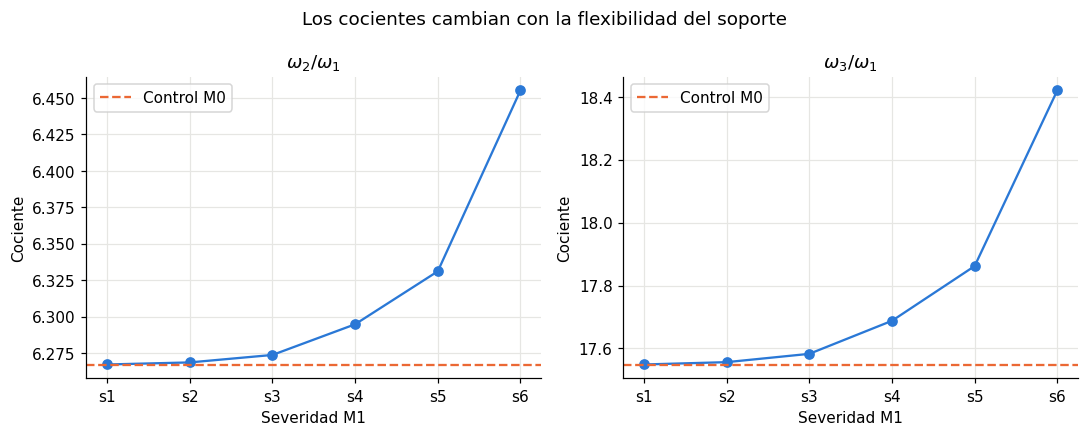

Variación máxima de los cocientes al cambiar E con soporte adimensional fijo: 3.55e-15


,nivel,kappa_theta,omega2/omega1,omega3/omega1
0,s1,396,6.27,17.5
1,s2,156,6.27,17.6
2,s3,76.1,6.27,17.6
3,s4,36.1,6.29,17.7
4,s5,22.8,6.33,17.9
5,s6,12.1,6.46,18.4


In [17]:
m1 = CALIBRACION[
    (CALIBRACION["generador"] == "M1")
    & (CALIBRACION["estructura"] == "voladizo")
    & CALIBRACION["nivel"].str.fullmatch(r"s[1-6]")
].copy()
m1["orden"] = m1["nivel"].str.extract(r"s(\d+)").astype(int)
m1 = m1.sort_values("orden").reset_index(drop=True)

filas = []
for fila in m1.itertuples():
    modos = resolver_modos(
        VIGA, "voladizo", Soporte(kappa_theta=float(fila.kappa_theta)), n_modos=3
    )
    razones = cocientes_frecuencia(modos.omega)
    filas.append({
        "nivel": fila.nivel,
        "kappa_theta": fila.kappa_theta,
        "omega2/omega1": razones[0],
        "omega3/omega1": razones[1],
    })
tabla_razones = pd.DataFrame(filas)

control = resolver_modos(VIGA, "voladizo", n_modos=3)
razon_m0 = cocientes_frecuencia(control.omega)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, columna, titulo, base in zip(
    ejes,
    ["omega2/omega1", "omega3/omega1"],
    [r"$\omega_2/\omega_1$", r"$\omega_3/\omega_1$"],
    razon_m0,
):
    ax.plot(tabla_razones["nivel"], tabla_razones[columna], "o-", color=COLORES[0])
    ax.axhline(base, color=COLORES[1], linestyle="--", label="Control M0")
    ax.set(title=titulo, xlabel="Severidad M1", ylabel="Cociente")
    ax.legend()
fig.suptitle("Los cocientes cambian con la flexibilidad del soporte")
fig.tight_layout()
plt.show()

# Verificación: al cambiar E con kappa_theta adimensional fijo, los cocientes no cambian.
s3 = float(m1.loc[m1["nivel"] == "s3", "kappa_theta"].iloc[0])
razones_por_E = np.stack([
    cocientes_frecuencia(
        resolver_modos(
            replace(VIGA, E=E),
            "voladizo",
            Soporte(kappa_theta=s3),
            n_modos=3,
        ).omega
    )
    for E in (35e9, 70e9, 105e9)
])
assert np.allclose(razones_por_E, razones_por_E[0], rtol=1e-9, atol=1e-12)
assert not np.allclose(tabla_razones.iloc[0, 2:].to_numpy(dtype=float), tabla_razones.iloc[-1, 2:].to_numpy(dtype=float))
print("Variación máxima de los cocientes al cambiar E con soporte adimensional fijo:",
      f"{np.max(np.abs(razones_por_E - razones_por_E[0])):.2e}")
display(tabla_razones.round(5))

## 2. Filtrado por varianza

Comparamos las formas modales de M1 entre s1 y s6 en 101 posiciones adimensionales. Para cada modo y posición calculamos la varianza entre severidades. Usamos como regla exploratoria conservar puntos cuya varianza sea al menos el 1 % del máximo de ese modo; mostramos también 0.5 % y 2 % para comprobar cuánto depende la selección del umbral.

La varianza mide cuánto cambia una observación en este barrido, pero no equivale por sí sola a información sobre todos los parámetros. La sensibilidad local se contrasta más adelante con Fisher.

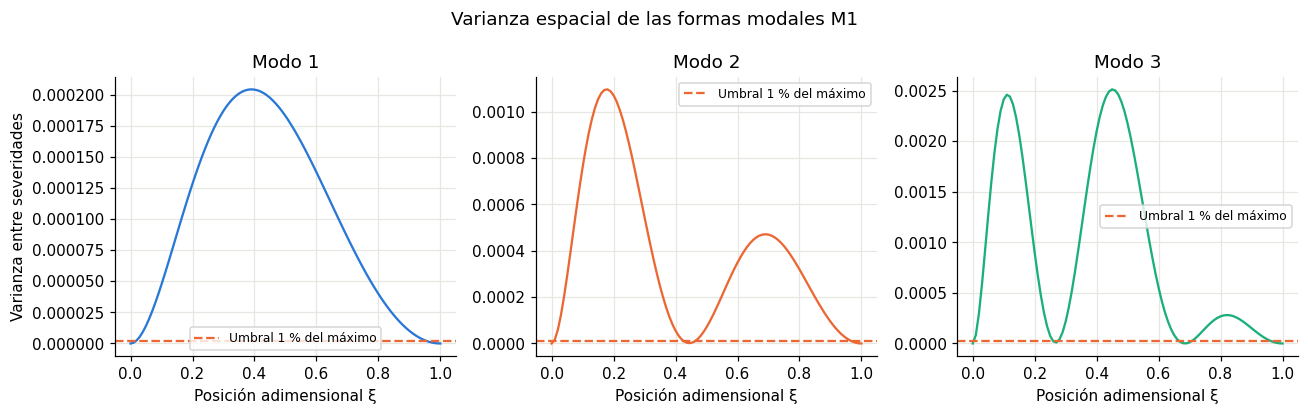

,Umbral relativo al máximo,Puntos modo 1,Puntos modo 2,Puntos modo 3
0,0.5 %,95,95,93
1,1 %,94,92,90
2,2 %,91,88,85


In [18]:
xi = np.linspace(0.0, 1.0, 101)
formas_m1 = np.stack([
    resolver_modos(
        VIGA, "voladizo", Soporte(kappa_theta=float(fila.kappa_theta)), n_modos=3
    ).forma(xi)
    for fila in m1.itertuples()
])
var_formas = varianza_formas(formas_m1)

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True)
for modo, ax in enumerate(ejes):
    ax.plot(xi, var_formas[modo], color=COLORES[modo])
    ax.axhline(0.01 * var_formas[modo].max(), color=COLORES[1], linestyle="--",
               label="Umbral 1 % del máximo")
    ax.set(title=f"Modo {modo + 1}", xlabel="Posición adimensional ξ")
    if modo == 0:
        ax.set_ylabel("Varianza entre severidades")
    ax.legend(fontsize=8)
fig.suptitle("Varianza espacial de las formas modales M1")
fig.tight_layout()
plt.show()

resumen_umbral = []
for umbral in (0.005, 0.01, 0.02):
    mascara = seleccionar_puntos_varianza(var_formas, fraccion_max=umbral)
    resumen_umbral.append({
        "Umbral relativo al máximo": f"{100 * umbral:g} %",
        **{f"Puntos modo {i + 1}": int(mascara[i].sum()) for i in range(3)},
    })
display(pd.DataFrame(resumen_umbral))

## 3. Correlación entre observaciones

El grupo sintético $k=3$ contiene un voladizo de 300 µm, una viga biempotrada de 300 µm y un voladizo de 200 µm. Se conserva el mismo anclaje físico al cambiar estructura y longitud: la rigidez adimensional del voladizo corto escala con $L$.

La matriz de correlación describe redundancia lineal a través de las seis severidades calibradas. Es un diagnóstico del diseño sintético, con solo seis niveles; por eso no se usa como regla automática para descartar variables.

/tmp/ipykernel_397/1943963193.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


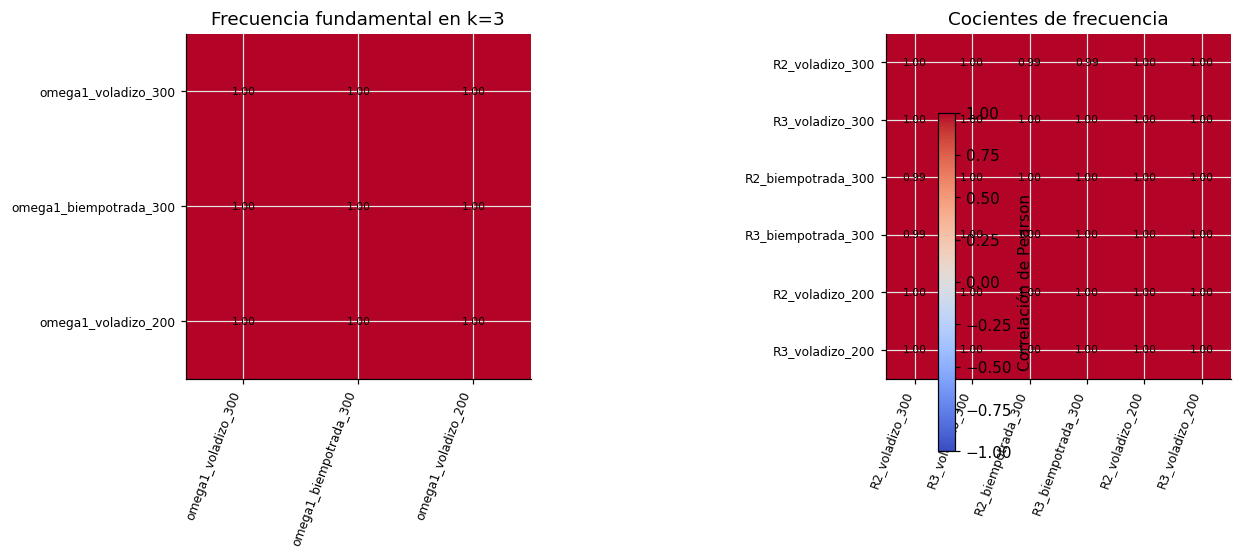

,omega1_voladizo_300,omega1_biempotrada_300,omega1_voladizo_200
omega1_voladizo_300,1,0.998,1
omega1_biempotrada_300,0.998,1,0.999
omega1_voladizo_200,1,0.999,1


In [19]:
registros = []
for fila in m1.itertuples():
    k300 = float(fila.kappa_theta)
    vigas = [
        ("voladizo 300", replace(VIGA, L=300e-6, sigma0=0.0), "voladizo", k300),
        ("biempotrada 300", replace(VIGA, L=300e-6, sigma0=-5e6), "biempotrada", k300),
        ("voladizo 200", replace(VIGA, L=200e-6, sigma0=0.0), "voladizo", k300 * 200 / 300),
    ]
    registro = {"severidad": fila.nivel}
    for nombre, viga, estructura, kappa in vigas:
        omega = resolver_modos(
            viga, estructura, Soporte(kappa_theta=kappa), n_modos=3
        ).omega
        prefijo = nombre.replace(" ", "_")
        for i, valor in enumerate(omega, start=1):
            registro[f"omega{i}_{prefijo}"] = valor
        razones = cocientes_frecuencia(omega)
        registro[f"R2_{prefijo}"] = razones[0]
        registro[f"R3_{prefijo}"] = razones[1]
    registros.append(registro)

grupo_k3 = pd.DataFrame(registros).set_index("severidad")
nombres_omega1 = [c for c in grupo_k3.columns if c.startswith("omega1_")]
nombres_razones = [c for c in grupo_k3.columns if c.startswith(("R2_", "R3_"))]
corr_omega1 = matriz_correlacion(grupo_k3[nombres_omega1].to_numpy())
corr_razones = matriz_correlacion(grupo_k3[nombres_razones].to_numpy())

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, corr, nombres, titulo in [
    (ejes[0], corr_omega1, nombres_omega1, "Frecuencia fundamental en k=3"),
    (ejes[1], corr_razones, nombres_razones, "Cocientes de frecuencia"),
]:
    imagen = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(nombres)), nombres, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(len(nombres)), nombres, fontsize=8)
    ax.set_title(titulo)
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(imagen, ax=ejes, label="Correlación de Pearson", shrink=0.8)
fig.tight_layout()
plt.show()
display(grupo_k3[nombres_omega1].corr().round(3))

## 4. Selección de ubicación y modos con Fisher

La matriz de Fisher aproxima cuánta información local aportan las frecuencias y formas para los parámetros del modelo. Comparamos tres ubicaciones de 15 puntos, con uno y tres modos, en s3. El supuesto de ruido es 2 % relativo a la amplitud modal y 0.03 % relativo en frecuencia.

La cota de Cramér–Rao es una aproximación local bajo esos supuestos; no es una medición del error real de un ajuste ni cubre aquí todos los parámetros del proyecto.

,Modos,Ubicación,Cota relativa E (%),Cota relativa κθ (%)
0,1,uniforme,5.12,102
1,1,anclaje,5.61,112
2,1,punta,6.11,122
3,3,uniforme,0.47,10.2
4,3,anclaje,0.47,10.1
5,3,punta,0.49,10.6


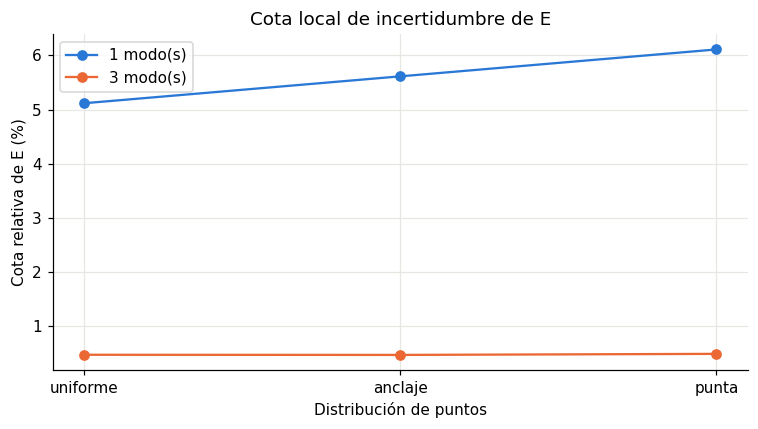

In [20]:
soporte_s3 = Soporte(kappa_theta=s3)
resultados_fisher = []
for n_modos in (1, 3):
    for esquema in ("uniforme", "anclaje", "punta"):
        F = fisher(
            VIGA, "voladizo", soporte_s3, puntos(esquema, 15), n_modos=n_modos
        )
        cota = cota_cramer_rao(F)
        resultados_fisher.append({
            "Modos": n_modos,
            "Ubicación": esquema,
            "Cota relativa E (%)": 100 * cota[0],
            "Cota relativa κθ (%)": 100 * cota[1],
        })
tabla_fisher = pd.DataFrame(resultados_fisher)
display(tabla_fisher.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for n_modos, color in zip((1, 3), COLORES[:2]):
    parte = tabla_fisher[tabla_fisher["Modos"] == n_modos]
    ax.plot(parte["Ubicación"], parte["Cota relativa E (%)"], "o-",
            color=color, label=f"{n_modos} modo(s)")
ax.set(xlabel="Distribución de puntos", ylabel="Cota relativa de E (%)",
       title="Cota local de incertidumbre de E")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Extracción con PCA

Alineamos y normalizamos las formas modales con la convención determinista del eigensolver. Restamos, modo por modo, la forma M0 de la forma M1 para cada severidad. El PCA resume las direcciones espaciales dominantes de esa desviación; retenemos el menor número de componentes que explica al menos 95 % de su variación en este barrido.

Este resultado caracteriza los datos sintéticos usados para construir la base. No demuestra por sí solo que una base reducida mejore la estimación de parámetros: eso se debe comprobar después en la fase de modelado.

Componentes para explicar al menos 95 %: 2


,Componente,Varianza explicada (%),Acumulada (%)
0,1,72.7,72.7
1,2,22.7,95.5
2,3,4.53,100
3,4,0,100
4,5,0,100
5,6,0,100
6,7,0,100
7,8,0,100
8,9,0,100
9,10,0,100


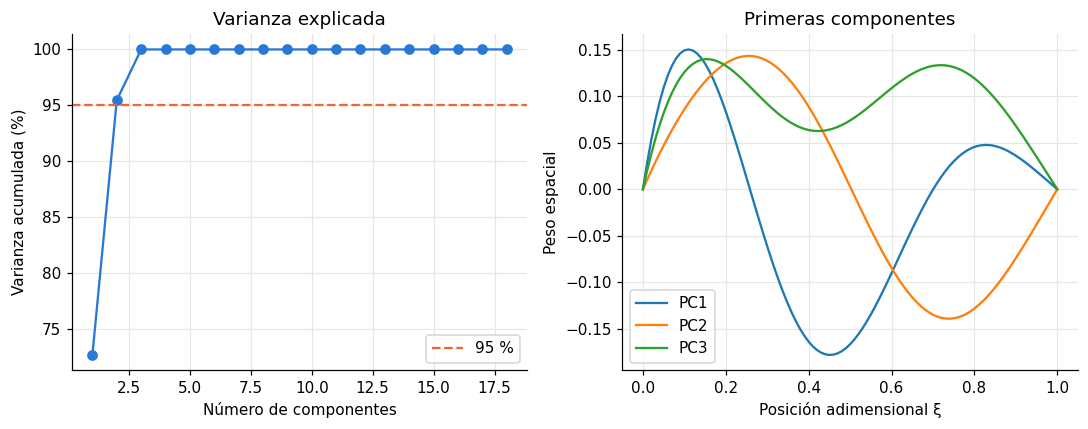

In [21]:
formas_m0 = control.forma(xi)
desviaciones = (formas_m1 - formas_m0[None, :, :]).reshape(-1, len(xi))
pca = pca_svd(desviaciones, varianza_objetivo=0.95)

print("Componentes para explicar al menos 95 %:", pca.n_componentes_objetivo)
display(pd.DataFrame({
    "Componente": np.arange(1, len(pca.varianza_explicada) + 1),
    "Varianza explicada (%)": 100 * pca.varianza_explicada,
    "Acumulada (%)": 100 * pca.varianza_acumulada,
}).round(2))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(
    np.arange(1, len(pca.varianza_acumulada) + 1),
    100 * pca.varianza_acumulada, "o-", color=COLORES[0],
)
ejes[0].axhline(95, color=COLORES[1], linestyle="--", label="95 %")
ejes[0].set(xlabel="Número de componentes", ylabel="Varianza acumulada (%)",
            title="Varianza explicada")
ejes[0].legend()
for i in range(min(3, len(pca.componentes))):
    ejes[1].plot(xi, pca.componentes[i], label=f"PC{i + 1}")
ejes[1].set(xlabel="Posición adimensional ξ", ylabel="Peso espacial",
            title="Primeras componentes")
ejes[1].legend()
fig.tight_layout()
plt.show()

### Combinaciones de parámetros bien y mal determinadas

El PCA también se aplica a la matriz de Fisher: sus vectores propios son combinaciones de $\ln E$ y $\ln \kappa_\theta$, y cada valor propio dice cuánta información traen los datos sobre esa combinación. La desviación estándar mínima a lo largo de cada dirección es $1/\sqrt{\text{valor propio}}$; una dirección con valor propio pequeño es una combinación que los datos casi no fijan.

Usamos el mismo caso de la sección anterior (s3, 15 puntos uniformes) con uno y tres modos. Las elipses muestran la región de una desviación estándar en el plano de los dos parámetros, en cambio relativo (%).

1 modo(s): número de condición = 2.93e+06, correlación entre ln E y ln κθ = -0.9999
3 modo(s): número de condición = 8.70e+04, correlación entre ln E y ln κθ = -0.9973


,Modos,Dirección,Combinación,Desviación mínima (%)
0,1,mejor determinada,+0.999·ln E +0.050·ln κθ,0.06
1,1,peor determinada,-0.050·ln E +0.999·ln κθ,103
2,3,mejor determinada,+0.999·ln E +0.046·ln κθ,0.035
3,3,peor determinada,-0.046·ln E +0.999·ln κθ,10.2


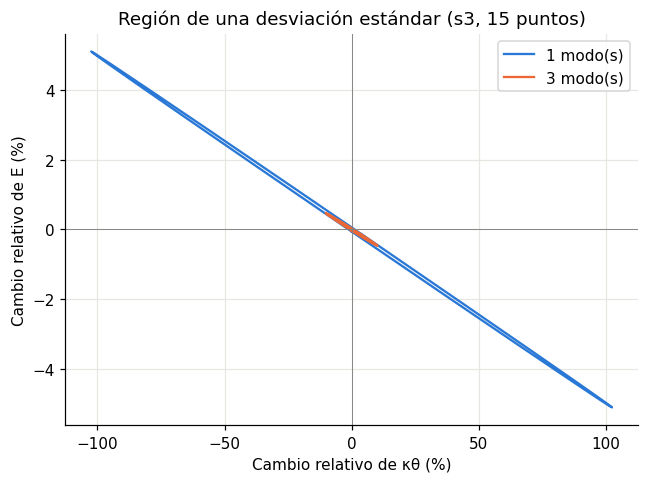

In [22]:
filas_dir = []
covarianzas = {}
for n_modos in (1, 3):
    F = fisher(VIGA, "voladizo", soporte_s3, puntos("uniforme", 15), n_modos=n_modos)
    direcciones = direcciones_fisher(F)
    covarianzas[n_modos] = np.linalg.inv(F)
    for i, nombre in enumerate(("mejor determinada", "peor determinada")):
        a, b = direcciones.vectores[:, i]
        filas_dir.append({
            "Modos": n_modos,
            "Dirección": nombre,
            "Combinación": f"{a:+.3f}·ln E {b:+.3f}·ln κθ",
            "Desviación mínima (%)": 100 * direcciones.desviacion[i],
        })
    print(f"{n_modos} modo(s): número de condición = {direcciones.condicion:.2e}, "
          f"correlación entre ln E y ln κθ = {covarianzas[n_modos][0, 1] / np.sqrt(covarianzas[n_modos][0, 0] * covarianzas[n_modos][1, 1]):+.4f}")
display(pd.DataFrame(filas_dir).round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
angulo = np.linspace(0, 2 * np.pi, 200)
circulo = np.vstack([np.cos(angulo), np.sin(angulo)])
for n_modos, color in zip((1, 3), COLORES[:2]):
    valores, vectores = np.linalg.eigh(covarianzas[n_modos])
    elipse = 100 * vectores @ (np.sqrt(valores)[:, None] * circulo)
    ax.plot(elipse[1], elipse[0], color=color, label=f"{n_modos} modo(s)")
ax.set(xlabel="Cambio relativo de κθ (%)", ylabel="Cambio relativo de E (%)",
       title="Región de una desviación estándar (s3, 15 puntos)")
ax.axhline(0, color="gray", lw=0.6)
ax.axvline(0, color="gray", lw=0.6)
ax.legend()
fig.tight_layout()
plt.show()

La dirección mejor determinada es casi $\ln E$ con un poco de $\ln \kappa_\theta$: es la combinación que fija la frecuencia, y los datos la acotan a menos de 0.1 %. La peor determinada es casi $\ln \kappa_\theta$ sola: con un modo su incertidumbre es del orden de 100 % y con tres modos baja a cerca de 10 %. Las dos estimaciones están casi perfectamente correlacionadas en sentido negativo (las elipses son tan alargadas que parecen líneas): un anclaje más flexible se puede compensar con un $E$ algo mayor. Por eso la cota de $E$ por sí sola (5 % con un modo) es mucho mayor que la de la dirección bien determinada: casi toda la incertidumbre de $E$ viene de no conocer el anclaje. Agregar modos es la forma de romper esa compensación.

## 6. Alcance y conclusión del frente clásico

En el barrido sintético, los cocientes de frecuencias separan cambios en el patrón modal de cambios comunes de escala; la varianza espacial y la correlación describen qué observaciones cambian juntas; Fisher compara la sensibilidad local a la ubicación y al número de modos, y sus direcciones propias muestran que $E$ queda bien acotado solo en combinación con la rigidez del anclaje, que se separa mejor con tres modos; PCA resume las desviaciones de forma respecto a M0. Estas técnicas guían la selección de características para la inversión y la representación de discrepancia.

Los resultados dependen del modelo sintético, de las seis severidades, de los niveles de ruido asumidos por Fisher y de las condiciones del soporte. La correlación con seis niveles es exploratoria y la cota de Fisher es local. El Brazo 1 real solo aporta una frecuencia por viga, de modo que no permite calcular cocientes de modos medidos. Las conclusiones de identificabilidad global deben apoyarse en el análisis conjunto de estructuras y parámetros del proyecto.

# Frente 3 — NIST Marshall

# Avance 2 — Ingeniería de características y análisis estadístico NIST

## Frente 3: Datos experimentales de Marshall y NIST

### Objetivo

Desarrollar y justificar técnicas de ingeniería de características para los datos experimentales del NIST, considerando la estructura de las mediciones, las variables físicas disponibles y las limitaciones del tamaño muestral.

El análisis se centra inicialmente en los 24 registros digitalizados de la Figura 6 de Marshall, correspondientes a ocho participantes y tres longitudes de voladizo (200, 300 y 400 µm). Se evalúan transformaciones de variables, codificación categórica, redundancia, posibles fugas de información y supuestos estadísticos.

Los resultados se interpretan como evidencia exploratoria para apoyar las decisiones de preparación de datos dentro de CRISP-ML(Q), sin asumir que las asociaciones observadas representan relaciones causales ni que las transformaciones propuestas constituyen un modelo predictivo validado.

## 2. Carga y validación de los datos

Se utiliza el conjunto de datos digitalizado de la Figura 6 de Marshall, disponible en el repositorio del proyecto. Este contiene mediciones del módulo de Young (`E_GPa`) para diferentes longitudes de voladizo (`L_um`), participantes, chips e instrumentos.

Antes de aplicar técnicas de ingeniería de características, se verifica la integridad estructural del conjunto de datos, incluyendo dimensiones, columnas requeridas, valores faltantes y duplicados.

La validación inicial permite identificar posibles problemas de calidad sin modificar los registros originales.

In [23]:

# ============================================================
# 2. CARGA Y VALIDACIÓN DE DATOS
# ============================================================

data_url = (
    "https://raw.githubusercontent.com/"
    "isabellaarangor/proyecto-integrador-team39-MNA/"
    "main/datos/nist/digitalizados/"
    "marshall_F6_reproducibilidad.csv"
)

df_marshall = pd.read_csv(data_url, comment="#")

required_columns = {
    "participant",
    "chip",
    "instrument",
    "L_um",
    "E_GPa",
    "x_px",
    "y_px",
}

missing_columns = required_columns - set(df_marshall.columns)

if missing_columns:
    raise ValueError(
        f"Faltan columnas requeridas: {sorted(missing_columns)}"
    )

print(f"Dimensiones: {df_marshall.shape}")
print(f"Registros duplicados: {df_marshall.duplicated().sum()}")

print("\nTipos de datos:")
display(df_marshall.dtypes.to_frame(name="Tipo"))

print("\nValores faltantes:")
display(df_marshall.isna().sum().to_frame(name="Faltantes"))

print("\nPrimeros registros:")
display(df_marshall.head(10))


Dimensiones: (24, 7)
Registros duplicados: 0

Tipos de datos:


,Tipo
participant,int64
chip,object
instrument,object
L_um,int64
E_GPa,float64
x_px,float64
y_px,float64



Valores faltantes:


,Faltantes
participant,0
chip,0
instrument,6
L_um,0
E_GPa,0
x_px,0
y_px,0



Primeros registros:


,participant,chip,instrument,L_um,E_GPa,x_px,y_px
0,1,chip 1,vibrómetro de doble haz,200,60.3,552,268
1,1,chip 1,vibrómetro de doble haz,300,65.6,561,244
2,1,chip 1,vibrómetro de doble haz,400,68.1,567,233
3,2,chip 1,vibrómetro de un haz,200,60.3,589,268
4,2,chip 1,vibrómetro de un haz,300,65.6,597,244
5,2,chip 1,vibrómetro de un haz,400,66.8,604,239
6,3,chip 1,interferómetro estroboscópico,200,60.3,626,268
7,3,chip 1,interferómetro estroboscópico,300,65.3,634,246
8,3,chip 1,interferómetro estroboscópico,400,67.4,641,236
9,4,chip 2,excitación PZT,200,58.3,670,277


## 3. Preparación e ingeniería de características

### 3.1. Tratamiento de valores faltantes y codificación categórica

Se genera una copia del conjunto de datos original para preservar su integridad. Los valores faltantes de la variable `instrument` se identifican mediante la categoría «No especificado», evitando atribuir un instrumento sin evidencia.

Las variables nominales `chip` e `instrument` se codifican mediante *one-hot encoding*, ya que sus categorías no poseen un orden natural.

Se conservan inicialmente los identificadores y las coordenadas de digitalización para fines de trazabilidad. Sin embargo, estas variables no se incorporarán a la matriz predictora final, pues no representan propiedades físicas independientes del experimento.

In [24]:

# ============================================================
# 3.1. LIMPIEZA Y CODIFICACIÓN CATEGÓRICA
# ============================================================

df_fe = df_marshall.copy()

# Identificar instrumentos sin información disponible.
df_fe["instrument"] = df_fe["instrument"].fillna(
    "No especificado"
)

# Codificar variables categóricas nominales.
df_encoded = pd.get_dummies(
    df_fe,
    columns=["chip", "instrument"],
    dtype=int,
)

print(f"Dimensiones originales: {df_marshall.shape}")
print(f"Dimensiones codificadas: {df_encoded.shape}")

print("\nValores faltantes después del tratamiento:")
display(df_encoded.isna().sum().to_frame(name="Faltantes"))

print("\nPrimeros registros codificados:")
display(df_encoded.head())


Dimensiones originales: (24, 7)
Dimensiones codificadas: (24, 15)

Valores faltantes después del tratamiento:


,Faltantes
participant,0
L_um,0
E_GPa,0
x_px,0
y_px,0
chip_chip 1,0
chip_chip 2,0
chip_chip 3,0
chip_chip 4,0
instrument_No especificado,0



Primeros registros codificados:


,participant,L_um,E_GPa,x_px,y_px,chip_chip 1,chip_chip 2,chip_chip 3,chip_chip 4,instrument_No especificado,instrument_excitación PZT,instrument_excitación térmica,instrument_interferómetro estroboscópico,instrument_vibrómetro de doble haz,instrument_vibrómetro de un haz
0,1,200,60.3,552,268,1,0,0,0,0,0,0,0,1,0
1,1,300,65.6,561,244,1,0,0,0,0,0,0,0,1,0
2,1,400,68.1,567,233,1,0,0,0,0,0,0,0,1,0
3,2,200,60.3,589,268,1,0,0,0,0,0,0,0,0,1
4,2,300,65.6,597,244,1,0,0,0,0,0,0,0,0,1


### 3.2. Generación de características derivadas

A partir de la longitud del voladizo (`L_um`) se generan tres representaciones adicionales:

- `L_mm`: longitud expresada en milímetros, como conversión de unidades.
- `L_squared`: longitud elevada al cuadrado, para explorar posibles relaciones no lineales.
- `L_inverse`: inverso de la longitud, para explorar relaciones inversas.

Estas transformaciones permiten evaluar distintas representaciones matemáticas de la longitud, pero no constituyen mediciones físicas independientes. Por ello, se analizará su redundancia antes de seleccionar las características que podrían utilizarse en etapas posteriores de modelado.

La inclusión de estas variables es exploratoria y no implica que todas deban conservarse simultáneamente.

In [25]:

# ============================================================
# 3.2. GENERACIÓN DE CARACTERÍSTICAS DERIVADAS
# ============================================================

df_encoded["L_mm"] = df_encoded["L_um"] / 1000.0
df_encoded["L_squared"] = df_encoded["L_um"] ** 2
df_encoded["L_inverse"] = 1.0 / df_encoded["L_um"]

derived_columns = [
    "L_um",
    "L_mm",
    "L_squared",
    "L_inverse",
    "E_GPa",
]

print("Características derivadas de la longitud:")
display(df_encoded[derived_columns].head(10))

print(f"\nDimensiones del conjunto: {df_encoded.shape}")


Características derivadas de la longitud:


,L_um,L_mm,L_squared,L_inverse,E_GPa
0,200,0.2,40000,0.005,60.3
1,300,0.3,90000,0.00333,65.6
2,400,0.4,160000,0.0025,68.1
3,200,0.2,40000,0.005,60.3
4,300,0.3,90000,0.00333,65.6
5,400,0.4,160000,0.0025,66.8
6,200,0.2,40000,0.005,60.3
7,300,0.3,90000,0.00333,65.3
8,400,0.4,160000,0.0025,67.4
9,200,0.2,40000,0.005,58.3



Dimensiones del conjunto: (24, 18)


### 3.3. Selección de características y prevención de fuga de información

Antes de realizar el escalamiento, se excluyen las variables que no deben formar parte de la matriz predictora:

- `participant`: identificador utilizado para reconocer las mediciones repetidas de cada participante.
- `x_px` y `y_px`: coordenadas provenientes del proceso de digitalización de la figura. No representan mediciones físicas independientes y podrían introducir información artificial sobre la variable objetivo.
- `L_mm`: conversión lineal de `L_um`, por lo que aporta información redundante.

La variable `E_GPa` se separa como objetivo del análisis.

Se conservan provisionalmente `L_um`, `L_squared` y `L_inverse`, junto con las categorías codificadas, para examinar su utilidad. Las transformaciones de longitud están matemáticamente relacionadas y no deben interpretarse como características independientes.

Esta selección es exploratoria. En un modelo predictivo posterior será necesario definir una estrategia de validación que respete la estructura de mediciones repetidas y ajustar cualquier transformación aprendida únicamente con los datos de entrenamiento.

In [26]:

# ============================================================
# 3.3. SELECCIÓN DE CARACTERÍSTICAS
# ============================================================

excluded_columns = [
    "participant",
    "x_px",
    "y_px",
    "L_mm",
    "E_GPa",
]

# Separar la variable objetivo sin modificar los datos originales.
y_selected = df_encoded["E_GPa"].copy()

# Excluir identificadores, coordenadas y variables redundantes.
X_selected = df_encoded.drop(
    columns=excluded_columns
).copy()

# Verificar la selección.
assert "E_GPa" not in X_selected.columns
assert "y_px" not in X_selected.columns
assert X_selected.isna().sum().sum() == 0

print(f"Dimensiones de X: {X_selected.shape}")
print(f"Dimensiones de y: {y_selected.shape}")

print("\nCaracterísticas seleccionadas:")
for column in X_selected.columns:
    print(f"- {column}")

print("\nPrimeros registros:")
display(X_selected.head())


Dimensiones de X: (24, 13)
Dimensiones de y: (24,)

Características seleccionadas:
- L_um
- chip_chip 1
- chip_chip 2
- chip_chip 3
- chip_chip 4
- instrument_No especificado
- instrument_excitación PZT
- instrument_excitación térmica
- instrument_interferómetro estroboscópico
- instrument_vibrómetro de doble haz
- instrument_vibrómetro de un haz
- L_squared
- L_inverse

Primeros registros:


,L_um,chip_chip 1,chip_chip 2,chip_chip 3,chip_chip 4,instrument_No especificado,instrument_excitación PZT,instrument_excitación térmica,instrument_interferómetro estroboscópico,instrument_vibrómetro de doble haz,instrument_vibrómetro de un haz,L_squared,L_inverse
0,200,1,0,0,0,0,0,0,0,1,0,40000,0.005
1,300,1,0,0,0,0,0,0,0,1,0,90000,0.00333
2,400,1,0,0,0,0,0,0,0,1,0,160000,0.0025
3,200,1,0,0,0,0,0,0,0,0,1,40000,0.005
4,300,1,0,0,0,0,0,0,0,0,1,90000,0.00333


### 3.4. Análisis de correlaciones y redundancia

Se calcula el coeficiente de correlación de Pearson entre las características numéricas seleccionadas y el módulo de Young (`E_GPa`) para identificar asociaciones lineales exploratorias.

Adicionalmente, se identifican pares de características con correlación absoluta superior a 0.95, como indicador de posible redundancia.

Es importante considerar que las transformaciones `L_um`, `L_squared` y `L_inverse` provienen de la misma variable original. Por tanto, una correlación elevada entre ellas es esperable y no implica que aporten información independiente.

Dado que las 24 observaciones incluyen mediciones repetidas de ocho participantes, las correlaciones se interpretan descriptivamente y no como evidencia inferencial independiente ni como criterios definitivos de selección para un modelo predictivo.

In [27]:

# ============================================================
# 3.4. CORRELACIONES Y REDUNDANCIA
# ============================================================

# Correlaciones de las características con la variable objetivo.
correlations = X_selected.corrwith(y_selected).dropna()

correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

correlation_summary = pd.DataFrame(
    {
        "Característica": correlations.index,
        "Correlación Pearson": correlations.values,
        "Correlación absoluta": correlations.abs().values,
    }
)

print("Correlaciones con el módulo de Young:")
display(correlation_summary.round(4))

# Identificar pares de características altamente correlacionadas.
correlation_matrix = X_selected.corr().abs()
redundant_pairs = []

for i, column_a in enumerate(correlation_matrix.columns):
    for column_b in correlation_matrix.columns[i + 1:]:
        correlation = correlation_matrix.loc[column_a, column_b]

        if correlation > 0.95:
            redundant_pairs.append(
                {
                    "Variable 1": column_a,
                    "Variable 2": column_b,
                    "Correlación": round(correlation, 4),
                }
            )

print("\nPares con correlación absoluta superior a 0.95:")

if redundant_pairs:
    display(pd.DataFrame(redundant_pairs))
else:
    print("No se identificaron pares que superen el umbral.")


Correlaciones con el módulo de Young:


,Característica,Correlación Pearson,Correlación absoluta
0,L_inverse,-0.902,0.902
1,L_um,0.882,0.882
2,L_squared,0.86,0.86
3,chip_chip 1,0.369,0.369
4,chip_chip 2,-0.318,0.318
5,instrument_excitación PZT,-0.245,0.245
6,instrument_vibrómetro de doble haz,0.208,0.208
7,instrument_interferómetro estroboscópico,0.17,0.17
8,instrument_vibrómetro de un haz,0.162,0.162
9,instrument_excitación térmica,-0.145,0.145



Pares con correlación absoluta superior a 0.95:


,Variable 1,Variable 2,Correlación
0,L_um,L_squared,0.995
1,L_um,L_inverse,0.982
2,L_squared,L_inverse,0.959


#### Interpretación y decisiones sobre las características

El análisis de correlación de Pearson muestra que las variables derivadas de la longitud presentan las asociaciones de mayor magnitud con el módulo de Young (`E_GPa`). La correlación más intensa corresponde a `L_inverse` (r = −0.9020), seguida de `L_um` (r = 0.8822) y `L_squared` (r = 0.8601).

Sin embargo, las tres representaciones de longitud presentan una redundancia elevada: las correlaciones absolutas entre ellas oscilan entre 0.9594 y 0.9954. Este resultado es consistente con que todas provienen de una misma variable física.

Las variables categóricas codificadas de chip e instrumento presentan asociaciones individuales de menor magnitud. Estas correlaciones no permiten establecer efectos independientes, particularmente porque las categorías pueden estar relacionadas con los participantes y las condiciones experimentales.

**Decisión de ingeniería de características:** se propone conservar `L_um` como representación principal de longitud en una matriz predictora inicial, manteniendo `L_inverse` y `L_squared` únicamente como alternativas para experimentos posteriores. No se recomienda incorporar las tres simultáneamente sin una justificación específica.

**Limitaciones:** los resultados son descriptivos y se calcularon sobre 24 mediciones correspondientes a ocho participantes. La dependencia entre observaciones impide interpretar estas correlaciones como pruebas inferenciales basadas en 24 muestras independientes. Además, la asociación estadística no demuestra causalidad ni garantiza capacidad de generalización.

## 4. Análisis estadístico de los datos experimentales

### 4.1. Estructura de las mediciones repetidas

Antes de realizar pruebas inferenciales, se examina la organización experimental de los datos digitalizados de Marshall.

El conjunto contiene 24 observaciones correspondientes a ocho participantes, con tres mediciones por participante para longitudes de 200, 300 y 400 µm.

Dado que las mediciones de un mismo participante pueden estar correlacionadas, no deben tratarse como observaciones independientes. Se utiliza un ANOVA de medidas repetidas para evaluar las diferencias del módulo de Young estimado entre longitudes, considerando al participante como unidad de repetición.

El análisis estadístico tiene un propósito exploratorio y está condicionado por el tamaño reducido de la muestra y la procedencia digitalizada de los datos.

In [28]:

# ============================================================
# 4.1. ESTRUCTURA DE LAS MEDICIONES REPETIDAS
# ============================================================

participant_summary = (
    df_marshall.groupby(["participant", "chip"])
    .agg(
        observations=("E_GPa", "size"),
        lengths=("L_um", "nunique"),
        mean_e_gpa=("E_GPa", "mean"),
        std_e_gpa=("E_GPa", "std"),
    )
    .reset_index()
)

print("Estructura experimental por participante:")
display(participant_summary.round(4))

print("\nParticipantes por chip:")
display(
    df_marshall.groupby("chip")["participant"]
    .nunique()
    .to_frame(name="Participantes")
)

print("\nLongitudes por participante:")
display(
    df_marshall.groupby("participant")["L_um"]
    .agg(lambda values: sorted(values.unique()))
    .to_frame(name="Longitudes (µm)")
)

# Validar el diseño de medidas repetidas.
expected_lengths = {200, 300, 400}

lengths_by_participant = df_marshall.groupby(
    "participant"
)["L_um"].agg(set)

assert len(lengths_by_participant) == 8
assert all(
    lengths == expected_lengths
    for lengths in lengths_by_participant
), "El diseño de medidas repetidas no está completo."

assert (
    df_marshall.groupby(["participant", "L_um"])
    .size()
    .eq(1)
    .all()
), "Se encontraron mediciones duplicadas por participante y longitud."

print("\nValidación del diseño experimental: correcta.")


Estructura experimental por participante:


,participant,chip,observations,lengths,mean_e_gpa,std_e_gpa
0,1,chip 1,3,3,64.7,3.96
1,2,chip 1,3,3,64.3,3.47
2,3,chip 1,3,3,64.3,3.63
3,4,chip 2,3,3,61.9,3.21
4,5,chip 2,3,3,61.5,3.59
5,6,chip 2,3,3,60.9,3.84
6,7,chip 3,3,3,61.8,3.29
7,8,chip 4,3,3,63.1,4.77



Participantes por chip:


,Participantes
chip,
chip 1,3
chip 2,3
chip 3,1
chip 4,1



Longitudes por participante:


,Longitudes (µm)
participant,
1,"[200, 300, 400]"
2,"[200, 300, 400]"
3,"[200, 300, 400]"
4,"[200, 300, 400]"
5,"[200, 300, 400]"
6,"[200, 300, 400]"
7,"[200, 300, 400]"
8,"[200, 300, 400]"



Validación del diseño experimental: correcta.


### 4.2. ANOVA de medidas repetidas

Se aplica un análisis de varianza (ANOVA) de medidas repetidas para evaluar si el módulo de Young estimado (`E_GPa`) presenta diferencias entre las tres longitudes del voladizo: 200, 300 y 400 µm.

**Hipótesis:**

- **H₀:** el promedio del módulo de Young estimado es igual para las tres longitudes.
- **H₁:** al menos una de las longitudes presenta un promedio diferente.

Se considera un nivel de significancia de α = 0.05.

El participante se utiliza como unidad de repetición para considerar la dependencia de las mediciones realizadas dentro de cada participante.

Posteriormente se examinarán los supuestos de normalidad y esfericidad, incluyendo la corrección de Greenhouse-Geisser cuando corresponda.

In [29]:

# ============================================================
# 4.2. ANOVA DE MEDIDAS REPETIDAS
# ============================================================

df_anova = df_marshall[
    ["participant", "L_um", "E_GPa"]
].copy()

# Tratar la longitud como factor categórico.
df_anova["L_um"] = df_anova["L_um"].astype(str)

anova_model = AnovaRM(
    data=df_anova,
    depvar="E_GPa",
    subject="participant",
    within=["L_um"],
)

anova_result = anova_model.fit()

print("Resultados del ANOVA de medidas repetidas:")
print(anova_result.summary())

print("\nEstadísticos principales:")
anova_table = anova_result.anova_table

f_statistic = anova_table.loc["L_um", "F Value"]
p_value = anova_table.loc["L_um", "Pr > F"]
df_num = anova_table.loc["L_um", "Num DF"]
df_den = anova_table.loc["L_um", "Den DF"]

print(f"F({df_num:.0f}, {df_den:.0f}) = {f_statistic:.4f}")
print(f"Valor p = {p_value:.8f}")
print(f"Significativo (α = 0.05): {p_value < 0.05}")


Resultados del ANOVA de medidas repetidas:
               Anova
     F Value  Num DF  Den DF Pr > F
-----------------------------------
L_um 294.2901 2.0000 14.0000 0.0000


Estadísticos principales:
F(2, 14) = 294.2901
Valor p = 0.00000000
Significativo (α = 0.05): True


### 4.3. Evaluación de normalidad mediante Shapiro-Wilk

Se aplica la prueba de Shapiro-Wilk para explorar la distribución del módulo de Young estimado en cada longitud del voladizo.

**Hipótesis:**

- **H₀:** los datos del grupo son compatibles con una distribución normal.
- **H₁:** los datos del grupo no siguen una distribución normal.

Se utiliza un nivel de significancia de α = 0.05.

Debido al tamaño reducido de cada grupo (n = 8), la prueba tiene una capacidad limitada para detectar desviaciones de normalidad. No rechazar la hipótesis nula no demuestra que los datos sean normales.

Además, como las mediciones corresponden a los mismos participantes, posteriormente se evaluará la normalidad de las diferencias entre longitudes, que resulta especialmente relevante para interpretar el diseño de medidas repetidas.

In [30]:

# ============================================================
# 4.3. NORMALIDAD POR LONGITUD
# ============================================================

shapiro_results = []

for length_um, group in df_marshall.groupby("L_um"):
    statistic, p_value_shapiro = shapiro(group["E_GPa"])

    shapiro_results.append(
        {
            "Longitud (µm)": length_um,
            "N": len(group),
            "Estadístico W": statistic,
            "Valor p": p_value_shapiro,
            "Decisión": (
                "No se rechaza H0"
                if p_value_shapiro >= 0.05
                else "Se rechaza H0"
            ),
        }
    )

df_shapiro = pd.DataFrame(shapiro_results)

print("Prueba de Shapiro-Wilk por longitud:")
display(
    df_shapiro.style.format(
        {
            "Estadístico W": "{:.4f}",
            "Valor p": "{:.6f}",
        }
    )
)


Prueba de Shapiro-Wilk por longitud:


,Longitud (µm),N,Estadístico W,Valor p,Decisión
0,200,8,0.8403,0.075821,No se rechaza H0
1,300,8,0.8885,0.226702,No se rechaza H0
2,400,8,0.8334,0.064403,No se rechaza H0


#### Interpretación de la normalidad por longitud

Los resultados de Shapiro-Wilk no proporcionan evidencia suficiente para rechazar la hipótesis de normalidad en ninguna de las tres longitudes evaluadas: 200 µm (W = 0.8403, p = 0.075821), 300 µm (W = 0.8885, p = 0.226702) y 400 µm (W = 0.8334, p = 0.064403).

Sin embargo, estos resultados deben interpretarse con cautela debido al tamaño muestral reducido (n = 8 por longitud). La ausencia de significancia estadística no garantiza que las distribuciones sean normales.

Por tanto, no se considera justificada una transformación automática de la variable objetivo mediante Box-Cox o Yeo-Johnson únicamente a partir de estas pruebas. La decisión deberá revisarse si se identifican problemas en los residuos de modelos posteriores.

Como siguiente comprobación, se evalúa la distribución de las diferencias entre las mediciones de un mismo participante, así como la esfericidad del diseño de medidas repetidas.

In [31]:

# ============================================================
# 4.4. NORMALIDAD DE DIFERENCIAS Y ESFERICIDAD
# ============================================================

df_wide = df_marshall.pivot(
    index="participant",
    columns="L_um",
    values="E_GPa",
)

length_pairs = [(200, 300), (200, 400), (300, 400)]
difference_results = []

for length_a, length_b in length_pairs:
    differences = df_wide[length_b] - df_wide[length_a]
    statistic, p_value_diff = shapiro(differences)

    difference_results.append(
        {
            "Comparación": f"{length_b} - {length_a} µm",
            "Diferencia media": differences.mean(),
            "Shapiro W": statistic,
            "Valor p": p_value_diff,
        }
    )

print("Normalidad de las diferencias entre longitudes:")
display(
    pd.DataFrame(difference_results).style.format(
        {
            "Diferencia media": "{:.4f}",
            "Shapiro W": "{:.4f}",
            "Valor p": "{:.6f}",
        }
    )
)

# Estimación del factor de corrección Greenhouse-Geisser.
covariance_matrix = np.cov(df_wide.to_numpy(), rowvar=False)
n_lengths = covariance_matrix.shape[0]

centering_matrix = (
    np.eye(n_lengths)
    - np.ones((n_lengths, n_lengths)) / n_lengths
)

centered_covariance = (
    centering_matrix
    @ covariance_matrix
    @ centering_matrix
)

epsilon_gg = np.trace(centered_covariance) ** 2 / (
    (n_lengths - 1)
    * np.trace(centered_covariance @ centered_covariance)
)

epsilon_gg = float(
    np.clip(epsilon_gg, 1 / (n_lengths - 1), 1.0)
)

corrected_df_num = df_num * epsilon_gg
corrected_df_den = df_den * epsilon_gg

corrected_p_value = f.sf(
    f_statistic,
    corrected_df_num,
    corrected_df_den,
)

print("\nCorrección de Greenhouse-Geisser:")
print(f"Epsilon: {epsilon_gg:.4f}")
print(
    "Grados de libertad corregidos: "
    f"({corrected_df_num:.4f}, {corrected_df_den:.4f})"
)
print(f"Valor p corregido: {corrected_p_value:.3e}")


Normalidad de las diferencias entre longitudes:


,Comparación,Diferencia media,Shapiro W,Valor p
0,300 - 200 µm,4.9675,0.9031,0.308170
1,400 - 200 µm,7.2475,0.8844,0.207560
2,400 - 300 µm,2.2800,0.9474,0.685165



Corrección de Greenhouse-Geisser:
Epsilon: 0.9100
Grados de libertad corregidos: (1.8200, 12.7402)
Valor p corregido: 3.105e-11


#### Interpretación de los supuestos y resultados del ANOVA

**Normalidad de las diferencias**

Las pruebas de Shapiro-Wilk aplicadas a las diferencias entre longitudes no permitieron rechazar la hipótesis de normalidad:

- 300 − 200 µm: W = 0.9031, p = 0.308170.
- 400 − 200 µm: W = 0.8844, p = 0.207560.
- 400 − 300 µm: W = 0.9474, p = 0.685165.

Estos resultados son compatibles con el supuesto de normalidad de las diferencias, aunque no lo demuestran debido al tamaño muestral reducido.

**Esfericidad y corrección de Greenhouse-Geisser**

Se obtuvo un factor epsilon de Greenhouse-Geisser de 0.9100, relativamente próximo a 1. Este resultado sugiere una desviación limitada respecto de la estructura de covarianza asociada con la esfericidad, pero no constituye por sí mismo una prueba formal de cumplimiento del supuesto.

Al aplicar la corrección, los grados de libertad se ajustaron a (1.8200, 12.7402) y se obtuvo un valor p de 3.105 × 10⁻¹¹.

**Resultado del ANOVA**

El ANOVA de medidas repetidas identificó diferencias estadísticamente significativas en el módulo de Young estimado entre las tres longitudes del voladizo: F(2, 14) = 294.2901, p < 0.001.

La conclusión se mantiene después de aplicar la corrección de Greenhouse-Geisser, por lo que el resultado es robusto frente a este ajuste de los grados de libertad.

Las diferencias medias observadas fueron:

- 300 − 200 µm: +4.9675 GPa.
- 400 − 200 µm: +7.2475 GPa.
- 400 − 300 µm: +2.2800 GPa.

Estas diferencias describen un aumento del módulo de Young estimado conforme aumenta la longitud en el conjunto analizado. No obstante, el ANOVA global no permite afirmar por sí solo que cada comparación individual sea estadísticamente significativa; para ello se requerirían contrastes pareados con corrección por comparaciones múltiples.

**Implicaciones para ingeniería de características**

Los resultados respaldan la relevancia de conservar la longitud del voladizo como característica explicativa. Sin embargo, las diferencias observadas pueden reflejar efectos asociados con el procedimiento experimental o la estimación del módulo de Young, y no necesariamente cambios en las propiedades intrínsecas del material.

Por tanto, la longitud se considera una característica relevante para etapas posteriores de modelado, manteniendo las precauciones correspondientes sobre dependencia entre mediciones y generalización.

### 4.5. Modelo mixto exploratorio

Se considera un modelo lineal mixto para explorar la relación del módulo de Young estimado con la longitud del voladizo y el chip utilizado.

La longitud y el chip se incluyen como efectos fijos, mientras que el participante se incorpora como intercepto aleatorio para representar la dependencia de sus mediciones repetidas.

Este análisis tiene carácter exploratorio debido al número reducido de participantes y al desequilibrio entre chips. En particular, los chips con un único participante no permiten distinguir adecuadamente los efectos asociados con el chip de los correspondientes al participante.

Se examinará la convergencia del ajuste y la varianza estimada del intercepto aleatorio. Si se presentan problemas de singularidad o estimaciones próximas a cero, los resultados no se utilizarán como evidencia confirmatoria de efectos independientes del chip.

In [32]:

# ============================================================
# 4.5. MODELO LINEAL MIXTO EXPLORATORIO
# ============================================================


df_mixed = df_marshall[
    ["participant", "chip", "L_um", "E_GPa"]
].copy()

df_mixed["length_factor"] = df_mixed["L_um"].astype(
    "category"
)

mixed_model = smf.mixedlm(
    "E_GPa ~ C(length_factor) + C(chip)",
    data=df_mixed,
    groups=df_mixed["participant"],
    eval_env=-1,
)

with warnings.catch_warnings(record=True) as model_warnings:
    warnings.simplefilter("always")

    try:
        mixed_result = mixed_model.fit(
            reml=True,
            method="lbfgs",
        )
    except (ValueError, np.linalg.LinAlgError) as error:
        mixed_result = None
        print(f"No fue posible ajustar el modelo: {error}")

if mixed_result is not None:
    print("Resumen del modelo mixto:")
    print(mixed_result.summary())

    print(f"\nConvergencia: {mixed_result.converged}")
    print(
        "Varianza del intercepto aleatorio: "
        f"{mixed_result.cov_re.iloc[0, 0]:.6f}"
    )

print("\nAdvertencias del ajuste:")
if model_warnings:
    for warning in model_warnings:
        print(f"- {warning.message}")
else:
    print("No se registraron advertencias.")


Resumen del modelo mixto:
               Mixed Linear Model Regression Results
Model:                 MixedLM     Dependent Variable:     E_GPa   
No. Observations:      24          Method:                 REML    
No. Groups:            8           Scale:                  0.3733  
Min. group size:       3           Log-Likelihood:         -21.7340
Max. group size:       3           Converged:              Yes     
Mean group size:       3.0                                         
-------------------------------------------------------------------
                        Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------------------
Intercept               60.346    0.279 216.409 0.000 59.800 60.893
C(length_factor)[T.300]  4.967    0.306  16.260 0.000  4.369  5.566
C(length_factor)[T.400]  7.247    0.306  23.723 0.000  6.649  7.846
C(chip)[T.chip 2]       -2.976    0.305  -9.742 0.000 -3.574 -2.377
C(chip)[T.chip 3]       -2.584    0.4

/usr/local/lib/python3.13/dist-packages/statsmodels/formula/formulatools.py:70: FutureWarning: EvalEnvironment is deprecated and support be removed in a future version. You can
pass variables using a dict[str, value] where str is the variable name and the
value is the array of values.

  result = mgr.get_matrices(


#### Interpretación y limitaciones del modelo mixto

El modelo lineal mixto convergió utilizando el método REML, con 24 observaciones distribuidas entre ocho participantes y tres mediciones por participante.

Los coeficientes asociados con la longitud fueron positivos respecto de la categoría de referencia de 200 µm: +4.967 GPa para 300 µm y +7.247 GPa para 400 µm. Estos resultados son consistentes con las diferencias descriptivas identificadas previamente mediante el ANOVA de medidas repetidas.

No obstante, el ajuste generó una advertencia de singularidad en la matriz de covarianza de los efectos aleatorios. La varianza estimada del intercepto por participante fue de 0.015498, frente a una varianza residual de 0.3733. Esto indica que el componente aleatorio estimado es pequeño y que su identificación puede resultar inestable con los datos disponibles.

Aunque el modelo produjo coeficientes y valores p para los distintos chips, estos resultados no deben interpretarse como evidencia confirmatoria de efectos independientes del chip. La distribución de participantes entre chips es desigual, y los chips 3 y 4 cuentan con un solo participante cada uno. Además, la pertenencia al chip no varía dentro de cada participante, lo que limita la separación de ambos efectos.

**Decisión metodológica:** se conserva el modelo mixto únicamente como análisis exploratorio y de sensibilidad. El ANOVA de medidas repetidas permanece como análisis principal para evaluar las diferencias asociadas con la longitud. No se utilizarán los coeficientes del modelo mixto para establecer conclusiones causales sobre el efecto del chip.

Para una evaluación más sólida de las diferencias entre chips sería necesario contar con un mayor número de participantes independientes por chip y un diseño experimental que permita separar las fuentes de variabilidad.

### 4.6. Comparación exploratoria entre chips mediante la prueba de Welch

Se realiza una comparación exploratoria del módulo de Young estimado entre los chips 1 y 2, utilizando la prueba t de Welch para dos grupos independientes.

Para evitar la pseudorreplicación, primero se calcula el promedio de las tres mediciones de cada participante. De esta manera, la unidad de análisis es el participante y no cada registro individual.

Se comparan únicamente los chips 1 y 2, dado que ambos cuentan con tres participantes. Los chips 3 y 4 se excluyen de esta comparación porque solamente tienen un participante cada uno.

**Hipótesis:**

- **H₀:** el promedio del módulo de Young estimado es igual entre los participantes de los chips 1 y 2.
- **H₁:** los promedios son diferentes.

La prueba de Welch no requiere asumir igualdad de varianzas entre los grupos. Sin embargo, el reducido tamaño muestral (n = 3 por chip) limita la precisión de las estimaciones y la evaluación de sus supuestos.

Este análisis es descriptivo e inferencial exploratorio. No permite atribuir causalmente las diferencias observadas al chip utilizado.

In [33]:

# ============================================================
# 4.6. COMPARACIÓN EXPLORATORIA ENTRE CHIPS
# ============================================================

# Obtener una observación promedio por participante.
df_participants = (
    df_marshall.groupby(
        ["participant", "chip"],
        as_index=False,
    )
    .agg(mean_e_gpa=("E_GPa", "mean"))
)

print("Módulo de Young promedio por participante:")
display(df_participants.round(4))

print("\nResumen descriptivo por chip:")
chip_summary = (
    df_participants.groupby("chip")["mean_e_gpa"]
    .agg(["count", "mean", "std"])
)

display(chip_summary.round(4))

# Comparar chips con tres participantes independientes.
chip_1 = df_participants.loc[
    df_participants["chip"] == "chip 1",
    "mean_e_gpa",
]

chip_2 = df_participants.loc[
    df_participants["chip"] == "chip 2",
    "mean_e_gpa",
]

assert len(chip_1) == 3
assert len(chip_2) == 3

t_statistic, p_value_welch = ttest_ind(
    chip_1,
    chip_2,
    equal_var=False,
)

mean_difference = chip_1.mean() - chip_2.mean()

print("\nPrueba t de Welch: chip 1 frente a chip 2")
print(f"Participantes por grupo: {len(chip_1)} y {len(chip_2)}")
print(f"Estadístico t: {t_statistic:.4f}")
print(f"Valor p: {p_value_welch:.6f}")
print(f"Diferencia de medias: {mean_difference:.4f} GPa")


Módulo de Young promedio por participante:


,participant,chip,mean_e_gpa
0,1,chip 1,64.7
1,2,chip 1,64.3
2,3,chip 1,64.3
3,4,chip 2,61.9
4,5,chip 2,61.5
5,6,chip 2,60.9
6,7,chip 3,61.8
7,8,chip 4,63.1



Resumen descriptivo por chip:


,count,mean,std
chip,,,
chip 1,3,64.4,0.215
chip 2,3,61.4,0.483
chip 3,1,61.8,NaN
chip 4,1,63.1,NaN



Prueba t de Welch: chip 1 frente a chip 2
Participantes por grupo: 3 y 3
Estadístico t: 9.7418
Valor p: 0.003204
Diferencia de medias: 2.9756 GPa


#### Interpretación de la comparación entre chips

La prueba t de Welch identificó una diferencia estadísticamente significativa entre los promedios del módulo de Young estimado para los participantes asociados con los chips 1 y 2 (t = 9.7418, p = 0.003204).

El chip 1 presentó un promedio de 64.4178 GPa, mientras que el chip 2 presentó un promedio de 61.4422 GPa, con una diferencia de 2.9756 GPa a favor del primero.

Para evitar pseudorreplicación, el análisis utilizó una única observación promedio por participante, con tres participantes independientes por chip.

A pesar de la significancia estadística, los resultados deben interpretarse con cautela debido al tamaño muestral reducido y a la posible confusión entre los efectos del chip, el participante y las condiciones experimentales. La prueba de Welch no corrige estos posibles factores de confusión.

Los chips 3 y 4 no se incluyeron en la comparación inferencial porque cada uno cuenta con un solo participante, lo que impide estimar adecuadamente la variabilidad entre participantes dentro de esos grupos.

**Implicación para ingeniería de características:** la variable `chip` puede conservarse como información contextual del experimento. Sin embargo, su utilidad predictiva deberá evaluarse mediante una estrategia de validación que evite compartir participantes entre entrenamiento y evaluación.

En consecuencia, esta comparación se considera exploratoria y no constituye evidencia causal de que un chip produzca valores diferentes del módulo de Young.

### 5. Resumen de decisiones de ingeniería de características

Esta sección sintetiza las técnicas de ingeniería de características y análisis estadístico evaluadas sobre el conjunto de datos digitalizados de NIST Marshall, compuesto por 24 observaciones correspondientes a ocho participantes y tres longitudes de voladizo.

Se distinguen las técnicas efectivamente aplicadas, los análisis realizados con fines exploratorios y los procedimientos descartados o pendientes para etapas posteriores de modelado.

Las decisiones se fundamentan en la naturaleza de las variables, la estructura de medidas repetidas, el tamaño muestral y la necesidad de preservar la interpretabilidad física de los resultados.

La tabla siguiente proporciona una justificación metodológica de cada decisión y permite identificar las transformaciones que deberán evaluarse posteriormente dentro de un proceso de entrenamiento y validación sin fuga de información.

In [34]:

# ============================================================
# 5. RESUMEN DE DECISIONES DE INGENIERÍA DE CARACTERÍSTICAS
# ============================================================

decisiones_fe = pd.DataFrame(
    [
        {
            "Técnica": "One-hot encoding",
            "Decisión": "Aplicada",
            "Justificación": (
                "Se codificaron chip e instrumento como "
                "variables nominales sin orden natural."
            ),
        },
        {
            "Técnica": "Características físicas",
            "Decisión": "Aplicada de forma exploratoria",
            "Justificación": (
                "Se generaron L_mm, L_squared y L_inverse "
                "para explorar distintas representaciones "
                "de la longitud."
            ),
        },
        {
            "Técnica": "Estandarización",
            "Decisión": "Pendiente para modelado",
            "Justificación": (
                "No se aplicó escalamiento a la matriz final. "
                "Si el algoritmo lo requiere, se ajustará "
                "únicamente con los datos de entrenamiento "
                "para evitar fuga de información."
            ),
        },
        {
            "Técnica": "Selección de características",
            "Decisión": "Preselección exploratoria",
            "Justificación": (
                "Se excluyeron identificadores, coordenadas "
                "de digitalización, la variable objetivo y "
                "L_mm. Se conservaron temporalmente L_um, "
                "L_squared y L_inverse para analizar su "
                "redundancia antes del modelado."
            ),
        },
        {
            "Técnica": "Correlación de Pearson",
            "Decisión": "Aplicada",
            "Justificación": (
                "Se evaluó la asociación lineal con E_GPa "
                "y la redundancia entre características. "
                "Los resultados son exploratorios debido "
                "a las mediciones repetidas."
            ),
        },
        {
            "Técnica": "ANOVA de medidas repetidas",
            "Decisión": "Aplicada",
            "Justificación": (
                "Se evaluaron las diferencias de E_GPa "
                "entre longitudes respetando la dependencia "
                "de las mediciones por participante."
            ),
        },
        {
            "Técnica": "Shapiro-Wilk",
            "Decisión": "Aplicada",
            "Justificación": (
                "Se examinó la normalidad de E_GPa por "
                "longitud y de las diferencias pareadas."
            ),
        },
        {
            "Técnica": "Greenhouse-Geisser",
            "Decisión": "Aplicada",
            "Justificación": (
                "Se ajustaron los grados de libertad del "
                "ANOVA para evaluar la robustez del resultado "
                "frente a posibles desviaciones de esfericidad."
            ),
        },
        {
            "Técnica": "Modelo lineal mixto",
            "Decisión": "Exploratorio",
            "Justificación": (
                "Se analizaron longitud y chip considerando "
                "un intercepto aleatorio por participante. "
                "La advertencia de singularidad limita "
                "la interpretación de los coeficientes."
            ),
        },
        {
            "Técnica": "Prueba t de Welch",
            "Decisión": "Exploratoria",
            "Justificación": (
                "Se compararon chips 1 y 2 usando un "
                "promedio por participante para evitar "
                "pseudorreplicación. Los grupos contienen "
                "tres participantes cada uno."
            ),
        },
        {
            "Técnica": "Box-Cox / Yeo-Johnson",
            "Decisión": "No aplicada",
            "Justificación": (
                "No se identificó una justificación "
                "suficiente para transformar E_GPa "
                "en esta etapa exploratoria."
            ),
        },
        {
            "Técnica": "Chi-cuadrada",
            "Decisión": "No aplicada",
            "Justificación": (
                "La variable objetivo es continua y "
                "no se planteó una prueba de asociación "
                "entre variables categóricas."
            ),
        },
        {
            "Técnica": "Discretización (binning)",
            "Decisión": "No aplicada",
            "Justificación": (
                "Se conservaron los valores numéricos "
                "para evitar pérdida de resolución."
            ),
        },
        {
            "Técnica": "PCA",
            "Decisión": "No aplicada",
            "Justificación": (
                "Con 24 observaciones se priorizó "
                "la interpretabilidad de las "
                "características físicas."
            ),
        },
    ]
)

display(decisiones_fe)


,Técnica,Decisión,Justificación
0,One-hot encoding,Aplicada,Se codificaron chip e instrumento como variabl...
1,Características físicas,Aplicada de forma exploratoria,"Se generaron L_mm, L_squared y L_inverse para ..."
2,Estandarización,Pendiente para modelado,No se aplicó escalamiento a la matriz final. S...
3,Selección de características,Preselección exploratoria,"Se excluyeron identificadores, coordenadas de ..."
4,Correlación de Pearson,Aplicada,Se evaluó la asociación lineal con E_GPa y la ...
5,ANOVA de medidas repetidas,Aplicada,Se evaluaron las diferencias de E_GPa entre lo...
6,Shapiro-Wilk,Aplicada,Se examinó la normalidad de E_GPa por longitud...
7,Greenhouse-Geisser,Aplicada,Se ajustaron los grados de libertad del ANOVA ...
8,Modelo lineal mixto,Exploratorio,Se analizaron longitud y chip considerando un ...
9,Prueba t de Welch,Exploratoria,Se compararon chips 1 y 2 usando un promedio p...


### 6. Conclusiones generales del análisis NIST Marshall

El análisis de los 24 registros digitalizados del estudio NIST Marshall permitió explorar la relación entre la longitud de los voladizos, el módulo de Young estimado y las condiciones experimentales asociadas con los participantes, chips e instrumentos.

**Principales hallazgos**

1. **Relevancia de la longitud:** la longitud del voladizo presentó una asociación importante con el módulo de Young estimado. El ANOVA de medidas repetidas identificó diferencias estadísticamente significativas entre longitudes (F(2, 14) = 294.2901, p < 0.001), resultado que se mantuvo después de aplicar la corrección de Greenhouse-Geisser (ε = 0.9100, p < 0.001).

2. **Ingeniería de características:** se aplicó codificación one-hot a las variables categóricas y se generaron representaciones físicas de la longitud (`L_mm`, `L_squared` y `L_inverse`). El análisis de correlación mostró una alta redundancia entre las representaciones de longitud, por lo que será necesario seleccionar una representación adecuada durante el modelado.

3. **Supuestos estadísticos:** las pruebas de Shapiro-Wilk no identificaron evidencia suficiente para rechazar la normalidad en los grupos por longitud ni en las diferencias pareadas. Sin embargo, el tamaño reducido de la muestra limita la capacidad de estas pruebas para detectar desviaciones.

4. **Variabilidad entre chips:** la prueba de Welch identificó una diferencia estadísticamente significativa entre los promedios de los chips 1 y 2 (p = 0.003204). No obstante, el reducido número de participantes y la posible confusión con las condiciones experimentales impiden atribuir causalmente esta diferencia al chip.

5. **Limitaciones del modelo mixto:** aunque el modelo convergió, presentó una advertencia de singularidad en la covarianza de los efectos aleatorios. Por ello, sus coeficientes se conservaron únicamente como resultados exploratorios.

**Decisiones para etapas posteriores**

Se prioriza conservar la longitud como característica explicativa, evaluar la utilidad de las variables categóricas y evitar incluir simultáneamente representaciones altamente redundantes sin una justificación de modelado.

Cualquier estandarización o selección de características basada en los datos deberá realizarse dentro del procedimiento de entrenamiento y validación, evitando fugas de información. Asimismo, las particiones deberán respetar la agrupación por participante para impedir que mediciones relacionadas aparezcan simultáneamente en entrenamiento y evaluación.

**Conclusión final**

Los resultados respaldan la relevancia de la longitud del voladizo para explicar la variación observada en el módulo de Young estimado. Sin embargo, esta relación no debe interpretarse como evidencia de cambios intrínsecos en la rigidez del material, ya que puede estar influida por el procedimiento experimental y de estimación.

Este análisis establece una base estadística y metodológica para integrar las características seleccionadas en las siguientes etapas del proyecto, manteniendo la interpretabilidad física y las precauciones derivadas del tamaño y la estructura del conjunto de datos.